### **ShortTerm Memory Implementation using InMemorySaver - Trimming**

In [1]:
from langgraph.graph import StateGraph, START, MessagesState
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages.utils import trim_messages,count_tokens_approximately

In [2]:
load_dotenv()

True

In [3]:
model = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

In [4]:
MAX_TOKENS = 200

In [17]:
# Define a function to call the model with the current state
def call_model(state: MessagesState):
    # Trim conversation history -> last N messages that fit within the token budget
    messages = trim_messages(
        state["messages"],
        strategy="last",                      
        token_counter=count_tokens_approximately,
        max_tokens=MAX_TOKENS
    )

    print('Current Token Count ->', count_tokens_approximately(messages=messages))

    for message in messages:
        print(message.content)

    response = model.invoke(messages)

    return {"messages": [response]}

In [18]:
#build graph with node and edge
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_edge(START, "call_model")

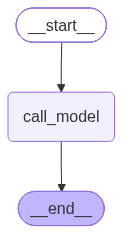

In [19]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)
graph

In [20]:
config = {"configurable": {"thread_id": "thread-1"}}
config2 = {"configurable": {"thread_id": "thread-2"}}

In [22]:
graph.invoke({"messages":[{"role": "user", "content": "Hi, I am Saurabh!"}]},config=config)

Current Token Count -> 18
Hi, I am Saurabh!
Hi, I am Saurabh!


{'messages': [HumanMessage(content='Hi, I am Saurabh!', additional_kwargs={}, response_metadata={}, id='9b5c5528-c947-4d0e-9e54-c07202e7cbb8'),
  HumanMessage(content='Hi, I am Saurabh!', additional_kwargs={}, response_metadata={}, id='ee65d64e-5747-4f6b-8522-31153472dd6b'),
  AIMessage(content='Hi Saurabh! Nice to meet you.\n\nHow can I help you today?', additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a17139-3fb0-7393-a98d-ce59e4d21f29-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 16, 'output_tokens': 129, 'total_tokens': 145, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 112}})]}

In [23]:
graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)

Current Token Count -> 46
Hi, I am Saurabh!
Hi, I am Saurabh!
Hi Saurabh! Nice to meet you.

How can I help you today?
What is my name?


{'messages': [HumanMessage(content='Hi, I am Saurabh!', additional_kwargs={}, response_metadata={}, id='9b5c5528-c947-4d0e-9e54-c07202e7cbb8'),
  HumanMessage(content='Hi, I am Saurabh!', additional_kwargs={}, response_metadata={}, id='ee65d64e-5747-4f6b-8522-31153472dd6b'),
  AIMessage(content='Hi Saurabh! Nice to meet you.\n\nHow can I help you today?', additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a17139-3fb0-7393-a98d-ce59e4d21f29-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 16, 'output_tokens': 129, 'total_tokens': 145, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 112}}),
  HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='ae3e7670-8c1c-4106-a00e-331c1f107256'),
  AIMessage(content='Based on our previous conversation, your name is **Saurabh**.', additional_

In [24]:
graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config2)

Current Token Count -> 8
What is my name?


{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='eecf5825-b139-48b9-aa01-008b551567ac'),
  AIMessage(content="As an AI, I don't have access to personal information about you, so I don't know your name.", additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a17139-b7f6-77b2-8a0a-ceedb055bf30-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 6, 'output_tokens': 466, 'total_tokens': 472, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 441}})]}

In [25]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "Can you explain short term memory?"}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 80
Hi, I am Saurabh!
Hi, I am Saurabh!
Hi Saurabh! Nice to meet you.

How can I help you today?
What is my name?
Based on our previous conversation, your name is **Saurabh**.
Can you explain short term memory?


'Short-term memory (STM) is a crucial component of our memory system, acting as a temporary storage space for a limited amount of information that we are actively using or thinking about at any given moment.\n\nHere\'s a breakdown of its key characteristics and functions:\n\n1.  **Limited Capacity:**\n    *   STM can only hold a small amount of information at one time.\n    *   A classic finding by psychologist George Miller (1956) suggests that the "magical number seven, plus or minus two" items is the average capacity for STM for unrelated items (e.g., digits, letters). This means most people can hold between 5 and 9 pieces of information.\n    *   However, we can increase this capacity through a process called **chunking**, where individual pieces of information are grouped into larger, more meaningful units (e.g., remembering a phone number as three chunks: 555-123-4567, rather than ten individual digits).\n\n2.  **Limited Duration:**\n    *   Information in STM is held for a very 

In [28]:
for item in graph.get_state({"configurable": {"thread_id": "thread-1"}}).values['messages']:
    print(item.content)
    print('-'*120)

Hi, I am Saurabh!
------------------------------------------------------------------------------------------------------------------------
Hi, I am Saurabh!
------------------------------------------------------------------------------------------------------------------------
Hi Saurabh! Nice to meet you.

How can I help you today?
------------------------------------------------------------------------------------------------------------------------
What is my name?
------------------------------------------------------------------------------------------------------------------------
Based on our previous conversation, your name is **Saurabh**.
------------------------------------------------------------------------------------------------------------------------
Can you explain short term memory?
------------------------------------------------------------------------------------------------------------------------
Short-term memory (STM) is a crucial component of our memory system